# Agents: figures of Lesson 11.01

- This notebook generates the figures of the slides
  `Lesson11.01_Agents_Automating_the_Research_Loop.smd` from simulated data,
  and saves them as PNG files
- The pedagogical arc:
  - Agents are stochastic: one run of an agent is one draw, so the score of
    an agent depends on how many runs are counted and how
  - Benchmarks are noisy: when agents differ by a point or two, the top of a
    leaderboard is often not the best agent

In [1]:
%load_ext autoreload
%autoreload 2

import logging

In [2]:
import helpers.hintrospection as hintros
import helpers.hmatplotlib as hmatplo
import helpers.hnotebook as hnotebook

import L11_01_agents_automating_the_research_loop_utils as utils

# Initialize notebook configuration and logging.
hnotebook.config_notebook()
_LOG = logging.getLogger(__name__)
utils.init_loggers(_LOG)

# Convert `display` into `print()` when running outside IPython.
try:
    from IPython.display import display
except ImportError:
    display = print  # type: ignore

INFO  > /Users/saggese/src/venv/client_venv.helpers/lib/python3.11/site-packages/ipykernel_launcher.py -f /private/var/folders/pd/0_nppqrn3cn7936mmhk37gcw0000gn/T/tmpc7rmmm3u.json --HistoryManager.hist_file=:memory:


In [3]:
# Directory of the figures, and prefix of the markdown reference to paste in the
# slides.
out_dir_name = "figures"
markdown_path_prefix = "book_Modern_AI_for_Finance/lectures_source"

# Size of a figure that fits a column of a slide.
figsize = (6.0, 4.0)

# Seed of all the simulations.
seed = 1

# Part 1: Evaluating agents

## Cell 1.1: Agents are stochastic

**Goal**
- Run an agent several times on each task of a benchmark, and count a task as
  solved in two ways
- See that "at least one run succeeds" rises with the number of runs, while
  "every run succeeds" falls

**Description**
- Inputs
  - `n_tasks`: number of tasks of the benchmark
  - `n_runs`: number of independent runs of each task
  - `max_k`: largest number of runs `k` on the x axis
  - `mean_success`: mean success probability of one run over the tasks
  - `concentration`: spread of the success probability across the tasks,
    where a small value makes some tasks always solved and some never solved
  - `seed`: seed of the random number generator

- Panels
  - `Runs`: pass@k in blue and pass^k in red against the number of runs `k`,
    with the success rate of a single run as a gray dashed line

pass@1=0.62 pass@8=0.94 pass^8=0.21
Saved figure to 'figures/L11.01.Pass_At_K.png'
![](book_Modern_AI_for_Finance/lectures_source/figures/L11.01.Pass_At_K.png)


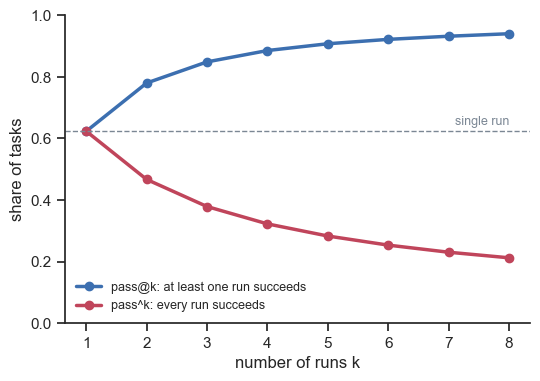

In [4]:
# Plot the pass@k and the pass^k against the number of runs.
fig = utils.cell1_1_plot_pass_at_k(
    n_tasks=400,
    n_runs=8,
    max_k=8,
    mean_success=0.6,
    concentration=2.0,
    seed=seed,
    figsize=figsize,
)
hmatplo.save_fig(
    fig,
    f"{out_dir_name}/L11.01.Pass_At_K.png",
    print_markdown=True,
    path_prefix=markdown_path_prefix,
)

**Guided usage**
- Change `concentration` from 2.0 to 1000.0
  - Observe pass^8 fall from 0.21 to 0.02: when every task has the same
    success probability $p$, pass^k is $p^k$, and no task is solved reliably
- Change `concentration` from 2.0 to 0.5
  - Observe pass^8 stay at 0.40 for a single-run score of 0.58: most tasks
    are either always or never solved, so the reliable share is large

**Implementation** `cell1_1_plot_pass_at_k()`
- Draws the success probability of each task from a Beta distribution with
  mean `mean_success`
- Simulates `n_runs` independent runs of each task
- Computes pass@k and pass^k with the unbiased estimators over all the subsets
  of `k` runs of each task, and averages them over the tasks

In [5]:
hintros.print_obj_info(utils.cell1_1_plot_pass_at_k)

- `cell1_1_plot_pass_at_k(*, n_tasks: int, n_runs: int, max_k: int, mean_success: float, concentration: float, seed: int, figsize: Optional[Tuple[float, float]] = None) -> matplotlib.figure.Figure`  
  Plot the pass@k and the pass^k of an agent against the number of runs.

https://github.com/gpsaggese/gpsaggese.github.io/blob/gp/book_Modern_AI_for_Finance/tutorials/L11_agents_automating_the_research_loop/L11_01_agents_automating_the_research_loop_utils.py#L150


## Cell 1.2: Benchmark rank noise

**Goal**
- Score five agents with close true accuracies on the same benchmark tasks
- See how many tasks a benchmark needs before its top-ranked agent is the
  true best one

**Description**
- Inputs
  - `n_agents`: number of agents on the leaderboard
  - `base_accuracy`: true accuracy of the weakest agent
  - `gaps`: accuracy gaps between neighboring agents, one curve each
  - `task_counts`: numbers of benchmark tasks on the x axis
  - `difficulty_std`: spread of the task difficulty, shared by all the agents
  - `n_sims`: number of simulated benchmarks per point
  - `seed`: seed of the random number generator

- Panels
  - `Ranks`: probability that the true best agent ranks first against the
    number of tasks on a log scale, one curve per gap, with the probability of
    a random pick as a gray dashed line

gap=0.010: 50: 0.31, 100: 0.36, 200: 0.41, 500: 0.54, 1000: 0.65, 2000: 0.75, 5000: 0.89


gap=0.030: 50: 0.54, 100: 0.66, 200: 0.74, 500: 0.88, 1000: 0.96, 2000: 0.99, 5000: 1.00
Saved figure to 'figures/L11.01.Benchmark_Rank_Noise.png'
![](book_Modern_AI_for_Finance/lectures_source/figures/L11.01.Benchmark_Rank_Noise.png)


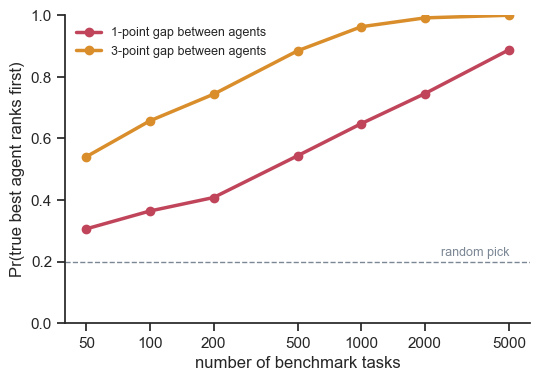

In [6]:
# Plot the probability of a correct winner against the number of tasks.
fig = utils.cell1_2_plot_benchmark_rank_noise(
    n_agents=5,
    base_accuracy=0.6,
    gaps=[0.01, 0.03],
    task_counts=[50, 100, 200, 500, 1000, 2000, 5000],
    difficulty_std=1.5,
    n_sims=2000,
    seed=seed,
    figsize=figsize,
)
hmatplo.save_fig(
    fig,
    f"{out_dir_name}/L11.01.Benchmark_Rank_Noise.png",
    print_markdown=True,
    path_prefix=markdown_path_prefix,
)

**Guided usage**
- Change `difficulty_std` from 1.5 to 0.1
  - Observe the 1-point curve at 500 tasks fall from 0.54 to 0.46: when the
    tasks have similar difficulty, the outcomes of the agents are less
    correlated, so the differences between the agents are noisier
- Change `gaps` to `[0.005, 0.01]`
  - Observe that a half-point gap needs about 2,000 tasks before the winner
    is the true best more often than not

**Implementation** `cell1_2_plot_benchmark_rank_noise()`
- Models the success probability of agent `i` on task `j` as
  `sigmoid(ability_i - difficulty_j)`, with a difficulty shared by all the
  agents
- Solves for the abilities that give the target mean accuracies
- Simulates `n_sims` benchmarks for each number of tasks, and counts how often
  the true best agent ranks first, with ties broken at random

In [7]:
hintros.print_obj_info(utils.cell1_2_plot_benchmark_rank_noise)

- `cell1_2_plot_benchmark_rank_noise(*, n_agents: int, base_accuracy: float, gaps: List[float], task_counts: List[int], difficulty_std: float, n_sims: int, seed: int, figsize: Optional[Tuple[float, float]] = None) -> matplotlib.figure.Figure`  
  Plot the probability that a benchmark ranks the true best agent first.

https://github.com/gpsaggese/gpsaggese.github.io/blob/gp/book_Modern_AI_for_Finance/tutorials/L11_agents_automating_the_research_loop/L11_01_agents_automating_the_research_loop_utils.py#L299
